# Clio-Infra at historical borders — the clients beneath the tools

`mcp.ipynb` reaches these series over SSE; this notebook uses the two Python
classes the tools wrap, with no server. They are the same classes that serve
`clio`, WONDER, NVSR and Voteview — `source="clio_historical"` is a column value.

**What is stored, and why so little.** Every DataverseNL deposit lists ~1,412
historical border periods, but in all except five indicators those rows are
empty — the deposit's data is its modern-state rows, which are the main site's
series, already stored as `clio`. What is stored here is the rest: **395 series,
one polity within one border period**, from exchange rates to the pound, days
lost in labour disputes, real wages, and one GDP row.

In [1]:
%reload_ext autoreload
%autoreload 2

import sys
sys.path.append("../")          # notebooks/clio_historical/, for utils
sys.path.append("../../../")    # meida, for mcp_server

import textwrap

import numpy
from matplotlib import pyplot

from lib import config
from utils import break_gaps, stamp_source
from mcp_server.series_catalog import SeriesCatalogClient
from mcp_server.timeseries_source import TimeSeriesSourceClient

pyplot.style.use(config.glyfish_style)

## How these series stand to the main site

Every series was compared with the main site's, value by value, and carries the
answer in its `relation` facet:

| relation | meaning |
| --- | --- |
| `same` | the same country on the main site carries every value |
| `successor` | the main site carries them under a modern state — Ottoman under Turkey |
| `differs` | the same-named country disagrees, because the borders do |
| `new` | the main site has none of it |

The comparison allows for rounding: the main site keeps seven significant
figures (`14.44252`), DataverseNL full precision (`14.4425187753`).

In [2]:
async with SeriesCatalogClient() as catalog:
    for relation in ("same", "successor", "differs", "new"):
        found, total = await catalog.search(source="clio_historical", limit=50,
                                            facets={"relation": relation})
        extra = "" if relation in ("same", "successor") else \
            "  " + ", ".join(sorted({e.title.split(" — ")[1] for e in found}))
        print(f"  {relation:10s} {total:4d}{extra}")

  same        352
  successor    38
  differs       1  Netherlands (borders 1820–1839)
  new           4  Falklands (borders 1840–1945), Hong Kong (borders 1860–1945), Yugoslavia (borders 1920–1945)


So numerically this source is almost entirely the main site's data, labelled
by the borders in force. What it adds is that label — the 1850 value is the
German Confederation's, not modern Germany's — plus four series the main site
lacks and one it gets different because its borders are different.

## One polity, several border periods

The Ottoman Empire's exchange rate to the pound, as the border periods divide
it. The main site files every one of these values under Turkey.

In [3]:
async with SeriesCatalogClient() as catalog:
    ottoman, _ = await catalog.search(source="clio_historical", limit=50,
                                      concept="exchange_rates_to_uk_pound",
                                      facets={"polity": "ottoman"})
ids = [e.series_id for e in sorted(ottoman, key=lambda e: e.facets["border_start"])]
async with TimeSeriesSourceClient() as store:
    refs = {r.native_id: r for r in await store.describe(ids)}
for i in ids:
    r = refs[i]
    e = next(e for e in ottoman if e.series_id == i)
    print(f"  borders {e.facets['border_start']}-{e.facets['border_end']}  "
          f"{r.observation_count:3d} obs  {e.facets['relation']:9s} "
          f"main site: {e.facets.get('modern_country', '-')}")

  borders 1780-1799    6 obs  successor main site: turkey
  borders 1800-1819   15 obs  successor main site: turkey
  borders 1820-1839   17 obs  successor main site: turkey
  borders 1840-1859    9 obs  successor main site: turkey
  borders 1860-1879   14 obs  successor main site: turkey
  borders 1880-1899   20 obs  successor main site: turkey
  borders 1900-1919   14 obs  successor main site: turkey
  borders 1920-1945   21 obs  successor main site: turkey


## What was left out

Canada's real-wage rows for 1925–1945 hold the United States' numbers, digit
for digit, and none of Canada's — a labelling error in the deposit. They were
never stored, so asking for them names them missing.

In [4]:
wanted = ["clio_historical/labourers_real_wage/canada_1880_1939",
          "clio_historical/labourers_real_wage/united_kingdom_1840_1939"]
async with TimeSeriesSourceClient() as store:
    found = {r.native_id for r in await store.describe(wanted)}
for i in wanted:
    print(f"  {'stored ' if i in found else 'MISSING'}  {i}")

  MISSING  clio_historical/labourers_real_wage/canada_1880_1939
  stored   clio_historical/labourers_real_wage/united_kingdom_1840_1939


## The one place the borders change the numbers

Between 1815 and 1830 the Netherlands included Belgium. The main site splits
them into two modern countries; this source keeps the kingdom as it was — and
its real wage is exactly two-thirds the Dutch series plus one-third the Belgian
in every year.

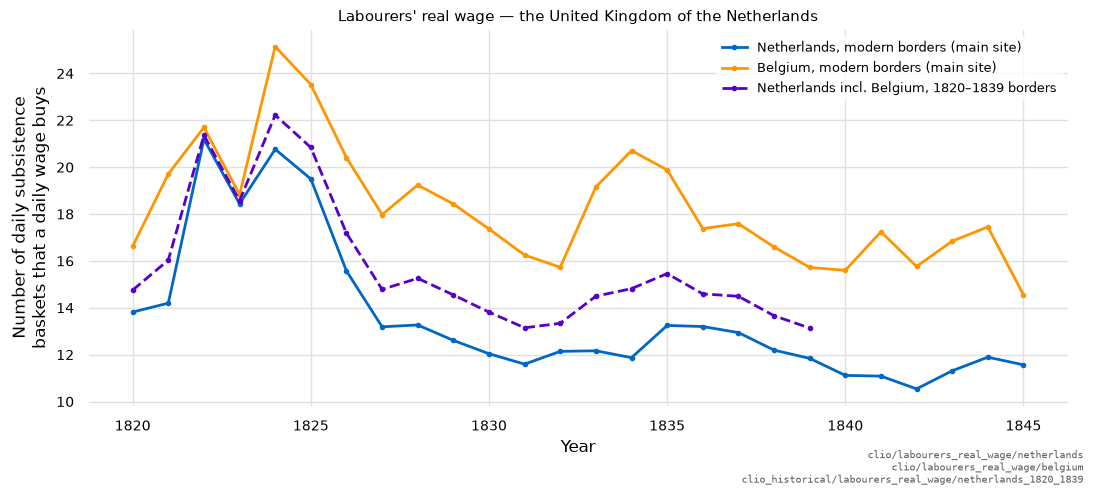

In [5]:
async with TimeSeriesSourceClient() as store:
    kingdom = await store.get_series("clio_historical",
                                     "clio_historical/labourers_real_wage/netherlands_1820_1839")
    dutch = await store.get_series("clio", "clio/labourers_real_wage/netherlands")
    belgian = await store.get_series("clio", "clio/labourers_real_wage/belgium")

def arrays(series, lo=1815, hi=1845):
    pts = [(int(o.date[:4]), float(o.value)) for o in series.observations if lo <= int(o.date[:4]) <= hi]
    return break_gaps(numpy.array([y for y, _ in pts]), numpy.array([v for _, v in pts]))

figure, axis = pyplot.subplots(figsize=(11, 5))
for series, label, style in ((dutch, "Netherlands, modern borders (main site)", "-"),
                             (belgian, "Belgium, modern borders (main site)", "-"),
                             (kingdom, "Netherlands incl. Belgium, 1820–1839 borders", "--")):
    axis.plot(*arrays(series), style, lw=2, marker="o", markersize=3, label=label)   # (x, y)
axis.set_ylabel(textwrap.fill(kingdom.units, 32))     # the unit is a sentence
axis.set_xlabel("Year")
axis.set_title("Labourers' real wage — the United Kingdom of the Netherlands", fontsize=11)
axis.legend(loc="upper right", fontsize=9)
figure.tight_layout()
stamp_source({"native_id": dutch.native_id}, {"native_id": belgian.native_id},
             {"native_id": kingdom.native_id}, figure=figure)

In [6]:
kd, du, be = (dict((int(o.date[:4]), float(o.value)) for o in s.observations) for s in (kingdom, dutch, belgian))
shares = [(kd[y] - du[y]) / (be[y] - du[y]) for y in kd if y in du and y in be and abs(be[y] - du[y]) > 0.5]
print(f"Belgian share of the kingdom's wage: {min(shares):.4f}-{max(shares):.4f} over {len(shares)} years")

Belgian share of the kingdom's wage: 0.3333-0.3333 over 19 years


For the same through the tools a model would call, see [`mcp.ipynb`](mcp.ipynb).